<a href="https://colab.research.google.com/github/AleBJ911/DeepLearning/blob/main/ProyectoEuroSatDataset/Avance1_ProyectoFinal_AlejandraBustos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto final — Primer avance: exploración de EuroSAT

**Problema.** Clasificar el uso y la cobertura del suelo a partir de imágenes satelitales Sentinel-2.

**Tarea.** Clasificación multiclase de imágenes (10 clases).

- **Entrada:** imagen RGB de 64 × 64 píxeles (parche de 640 m × 640 m, 10 m por píxel).
- **Salida:** probabilidad de cada una de las 10 clases (softmax).

**Fuente:** [EuroSAT Dataset (Kaggle, apollo2506)](https://www.kaggle.com/datasets/apollo2506/eurosat-dataset),
basado en Helber et al. (2019), *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*, IEEE JSTARS.

> En este avance todavía no se entrena ningún modelo. El objetivo es examinar los datos y extraer implicaciones para el diseño de los modelos.

## 1. Descarga e inventario de archivos

In [1]:
import os, glob, json, hashlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True})

CLASSES = ["AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
           "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"]
IMG_EXT = (".jpg", ".jpeg", ".png")

# Descarga desde Kaggle: https://www.kaggle.com/datasets/apollo2506/eurosat-dataset
# kagglehub descarga datasets públicos. Si pide credenciales, sube tu kaggle.json
# o define KAGGLE_USERNAME y KAGGLE_KEY en los "Secrets" de Colab.
import kagglehub
BASE = kagglehub.dataset_download("apollo2506/eurosat-dataset")
print("Descargado en:", BASE)


def find_rgb_root(base):
    """Carpeta que contiene las 10 subcarpetas de clase con imágenes RGB (JPG)."""
    for root, dirs, _ in os.walk(base):
        if set(CLASSES) <= set(dirs):
            files = os.listdir(os.path.join(root, CLASSES[0]))
            if any(f.lower().endswith(IMG_EXT) for f in files):
                return root
    raise FileNotFoundError("No se encontró la carpeta RGB con las 10 clases")


RGB_ROOT = find_rgb_root(BASE)
print("Carpeta RGB:", RGB_ROOT)

rows = []
for label, cls in enumerate(CLASSES):
    for f in sorted(os.listdir(os.path.join(RGB_ROOT, cls))):
        if f.lower().endswith(IMG_EXT):
            rows.append({"filepath": os.path.join(RGB_ROOT, cls, f),
                         "rel": f"{cls}/{f}", "label": label, "clase": cls})
df = pd.DataFrame(rows)
print("Imágenes encontradas:", len(df))

Using Colab cache for faster access to the 'eurosat-dataset' dataset.
Descargado en: /kaggle/input/eurosat-dataset
Carpeta RGB: /kaggle/input/eurosat-dataset/EuroSAT
Imágenes encontradas: 27000


In [2]:
# Estructura de la descarga: carpetas y archivos auxiliares
for root, dirs, files in os.walk(BASE):
    depth = root[len(BASE):].count(os.sep)
    if depth <= 2:
        extra = [f for f in files if not f.lower().endswith(IMG_EXT + (".tif",))]
        n_img = sum(f.lower().endswith(IMG_EXT + (".tif",)) for f in files)
        print("  " * depth + os.path.basename(root) + "/", f"({n_img} imágenes)" if n_img else "", extra[:6])

eurosat-dataset/  []
  EuroSATallBands/  ['validation.csv', 'train.csv', 'test.csv', 'label_map.json']
    SeaLake/ (3597 imágenes) []
    Highway/ (2500 imágenes) []
    River/ (2500 imágenes) []
    Pasture/ (2000 imágenes) []
    Industrial/ (2500 imágenes) []
    Residential/ (3000 imágenes) []
    PermanentCrop/ (2500 imágenes) []
    AnnualCrop/ (3000 imágenes) []
    Forest/ (3000 imágenes) []
    HerbaceousVegetation/ (3000 imágenes) []
  EuroSAT/  ['validation.csv', 'train.csv', 'test.csv', 'label_map.json']
    SeaLake/ (3000 imágenes) []
    Highway/ (2500 imágenes) []
    River/ (2500 imágenes) []
    Pasture/ (2000 imágenes) []
    Industrial/ (2500 imágenes) []
    Residential/ (3000 imágenes) []
    PermanentCrop/ (2500 imágenes) []
    AnnualCrop/ (3000 imágenes) []
    Forest/ (3000 imágenes) []
    HerbaceousVegetation/ (3000 imágenes) []


## 2. Calidad de datos: faltantes, ilegibles, dimensiones y duplicados

En imágenes, "datos faltantes" significa: archivos sin etiqueta, etiquetas sin archivo, o archivos que no se pueden abrir.
Se revisan también las dimensiones y los duplicados exactos.

In [4]:
def load_images(paths):
    """Carga todas las imágenes como uint8 (N, 64, 64, 3) y calcula su hash MD5."""
    X = np.empty((len(paths), 64, 64, 3), dtype=np.uint8)
    hashes, sizes, modes, bad = [], [], [], []
    for i, p in enumerate(paths):
        with open(p, "rb") as fh:
            raw = fh.read()
        hashes.append(hashlib.md5(raw).hexdigest())
        try:
            img = Image.open(p)
            sizes.append(img.size); modes.append(img.mode)
            img = img.convert("RGB")
            if img.size != (64, 64):
                img = img.resize((64, 64))
            X[i] = np.asarray(img)
        except Exception as e:
            bad.append((p, str(e))); sizes.append(None); modes.append(None)
    return X, hashes, sizes, modes, bad


t0 = time.time()
X_all, hashes, sizes, modes, bad = load_images(df["filepath"].tolist())
df["md5"], df["size"], df["mode"] = hashes, sizes, modes
y_all = df["label"].to_numpy()
print(f"Cargadas {len(X_all)} imágenes en {time.time()-t0:.1f} s -> {X_all.shape}, {X_all.nbytes/1e6:.0f} MB")
print("Imágenes ilegibles:", len(bad))

Cargadas 27000 imágenes en 153.0 s -> (27000, 64, 64, 3), 332 MB
Imágenes ilegibles: 0


In [5]:
# Dimensiones y modo de color
print("Tamaños encontrados:")
print(df["size"].value_counts(dropna=False).to_string())
print("\nModos de color:")
print(df["mode"].value_counts(dropna=False).to_string())

# Etiquetas faltantes: cada imagen debe tener clase (viene de su carpeta)
print("\nValores nulos por columna:")
print(df[["filepath", "label", "clase"]].isna().sum().to_string())

Tamaños encontrados:
size
(64, 64)    27000

Modos de color:
mode
RGB    27000

Valores nulos por columna:
filepath    0
label       0
clase       0


In [6]:
# Los CSV del dataset (train/validation/test) deben corresponder a archivos existentes
csv_dir = os.path.dirname(RGB_ROOT) if not glob.glob(os.path.join(RGB_ROOT, "*.csv")) else RGB_ROOT
csvs = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob(os.path.join(csv_dir, "*.csv"))}
print("CSV encontrados:", list(csvs))

csv_frames = {}
for name, p in csvs.items():
    c = pd.read_csv(p)
    c = c.loc[:, ~c.columns.str.startswith("Unnamed")]   # el README indica quitar la columna índice
    csv_frames[name] = c
    print(f"\n{name}: {len(c)} filas, columnas {list(c.columns)}")
    print("  nulos:", int(c.isna().sum().sum()))
    if "Filename" in c.columns:
        missing = (~c["Filename"].isin(df["rel"])).sum()
        print("  filas cuyo archivo no existe:", int(missing))

if csv_frames and all("Filename" in c.columns for c in csv_frames.values()):
    en_csv = pd.concat(csv_frames.values())["Filename"]
    print("\nImágenes que no aparecen en ningún CSV:", int((~df["rel"].isin(en_csv)).sum()))
    print("Archivos repetidos entre CSV:", int(en_csv.duplicated().sum()))

CSV encontrados: ['validation', 'train', 'test']

validation: 5400 filas, columnas ['Filename', 'Label', 'ClassName']
  nulos: 0
  filas cuyo archivo no existe: 0

train: 18900 filas, columnas ['Filename', 'Label', 'ClassName']
  nulos: 0
  filas cuyo archivo no existe: 0

test: 2700 filas, columnas ['Filename', 'Label', 'ClassName']
  nulos: 0
  filas cuyo archivo no existe: 0

Imágenes que no aparecen en ningún CSV: 0
Archivos repetidos entre CSV: 0


In [7]:
# Duplicados exactos por contenido
dup_mask = df["md5"].duplicated(keep=False)
grupos = df[dup_mask].groupby("md5")
print("Imágenes con contenido duplicado:", int(dup_mask.sum()), "en", grupos.ngroups, "grupos")
if grupos.ngroups:
    conflicto = grupos["clase"].nunique()
    print("Grupos de duplicados con clases distintas (etiqueta contradictoria):", int((conflicto > 1).sum()))
    display(df[dup_mask].sort_values("md5")[["rel", "clase", "md5"]].head(12))

# Imágenes casi vacías (un solo color), que no aportan información
std_px = X_all.reshape(len(X_all), -1).std(axis=1)
print("Imágenes con desviación de píxel < 2 (casi constantes):", int((std_px < 2).sum()))

Imágenes con contenido duplicado: 0 en 0 grupos
Imágenes con desviación de píxel < 2 (casi constantes): 3


## 3. Distribución de clases

Se cuenta el número de ejemplos por clase para detectar desbalance.

,% validation,% train,% test
ClassName,,,
AnnualCrop,11.11,11.11,11.11
Forest,11.11,11.11,11.11
HerbaceousVegetation,11.11,11.11,11.11
Highway,9.26,9.26,9.26
Industrial,9.26,9.26,9.26
Pasture,7.41,7.41,7.41
PermanentCrop,9.26,9.26,9.26
Residential,11.11,11.11,11.11
River,9.26,9.26,9.26


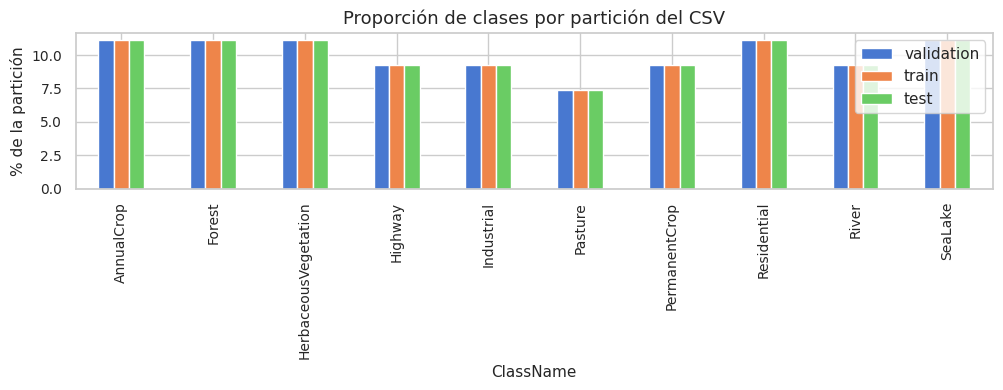

In [16]:
# Distribución de clases en los CSV de partición que trae el dataset (si existen)
if csv_frames and all("ClassName" in c.columns for c in csv_frames.values()):
    part = pd.DataFrame({k: v["ClassName"].value_counts() for k, v in csv_frames.items()}).reindex(CLASSES)
    display((100 * part / part.sum()).round(2).rename(columns=lambda c: f"% {c}"))
    (100 * part / part.sum()).plot.bar(figsize=(10, 4))
    plt.ylabel("% de la partición"); plt.title("Proporción de clases por partición del CSV")
    plt.tight_layout(); plt.show()

## 4. Ejemplos por clase

Se muestran 6 imágenes aleatorias de cada clase con su etiqueta.

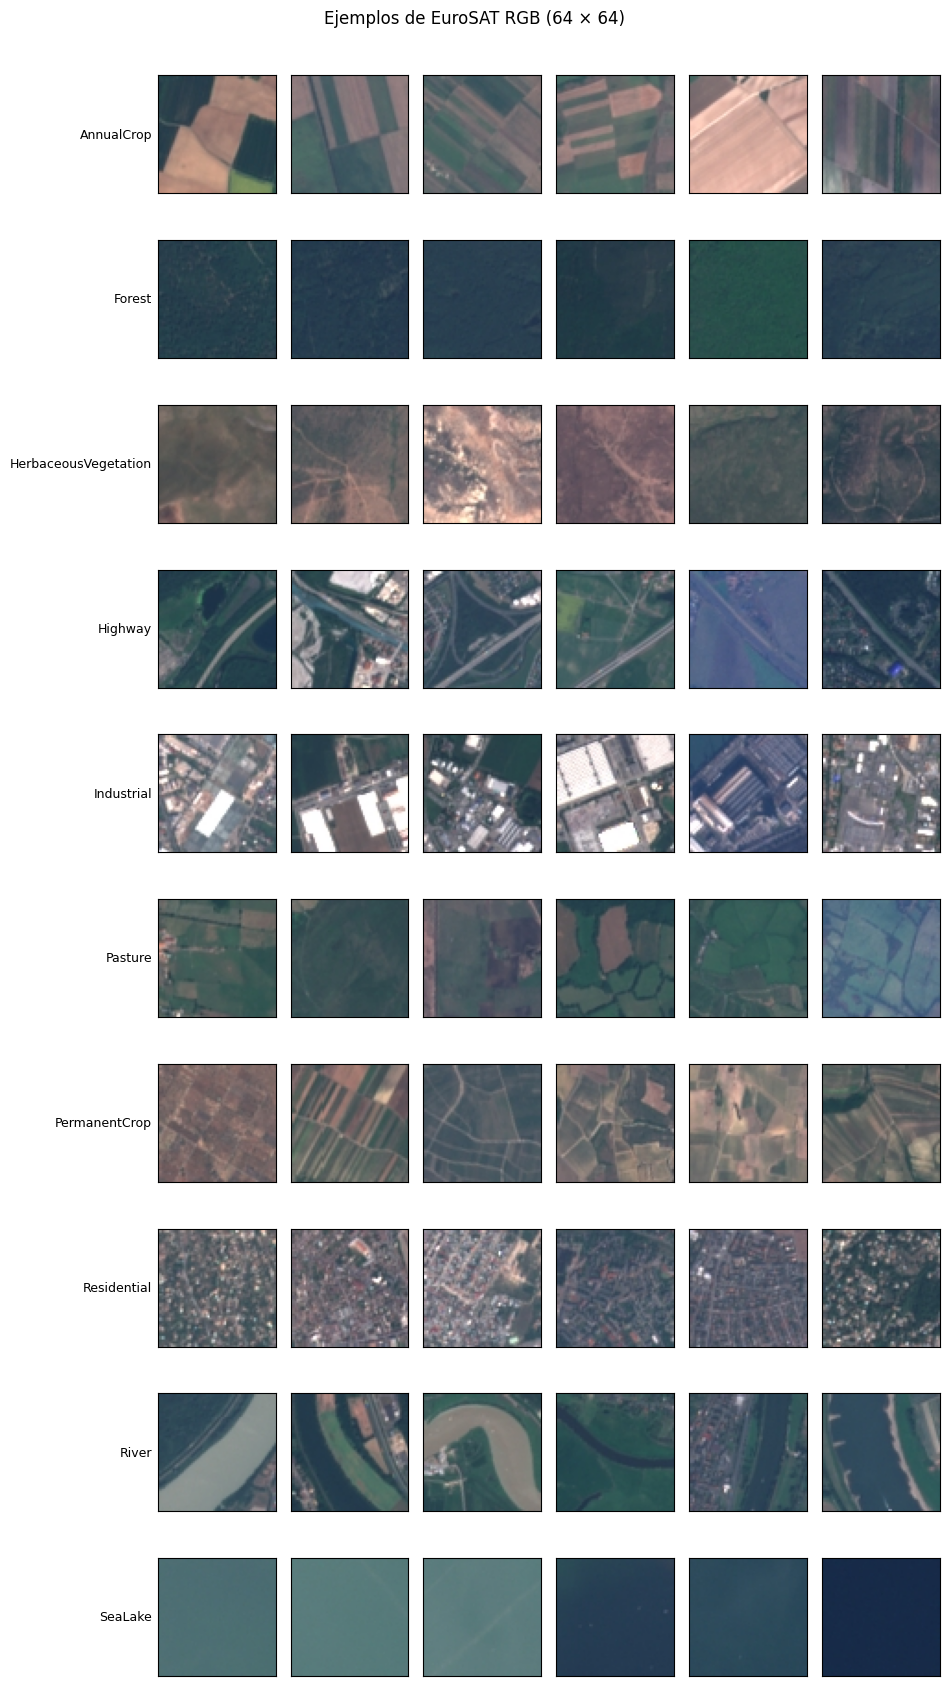

In [10]:
rng = np.random.default_rng(SEED)
n_cols = 6
fig, axes = plt.subplots(len(CLASSES), n_cols, figsize=(n_cols * 1.6, len(CLASSES) * 1.7))
for r, cls in enumerate(CLASSES):
    idx = rng.choice(np.where(y_all == r)[0], n_cols, replace=False)
    for c, i in enumerate(idx):
        ax = axes[r, c]
        ax.imshow(X_all[i]); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        if c == 0:
            ax.set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("Ejemplos de EuroSAT RGB (64 × 64)", y=1.0)
plt.tight_layout(); plt.show()

## 5. Características de color y brillo por clase

Aunque las entradas son píxeles, se pueden resumir con estadísticas por imagen: intensidad media por canal y brillo.
Esto muestra qué clases se separan solo por color y cuáles requieren aprender textura y forma.

,R,G,B,brillo,contraste
clase,,,,,
AnnualCrop,129.6,120.0,117.2,122.3,30.6
Forest,39.4,64.5,76.0,59.9,16.1
HerbaceousVegetation,98.2,98.7,103.9,100.3,18.2
Highway,88.0,96.7,103.4,96.0,25.7
Industrial,123.4,125.4,134.3,127.7,42.7
Pasture,61.9,88.5,94.2,81.5,18.5
PermanentCrop,122.1,116.0,114.0,117.4,24.7
Residential,100.1,103.8,113.0,105.6,23.4
River,67.0,86.6,96.9,83.5,24.4


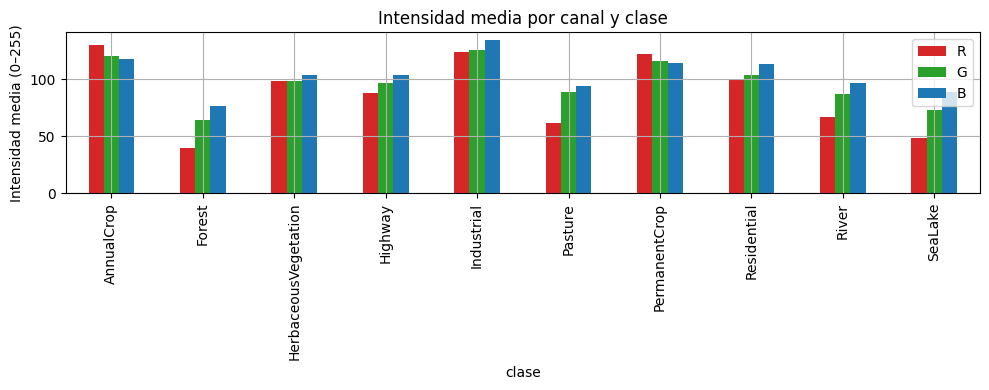

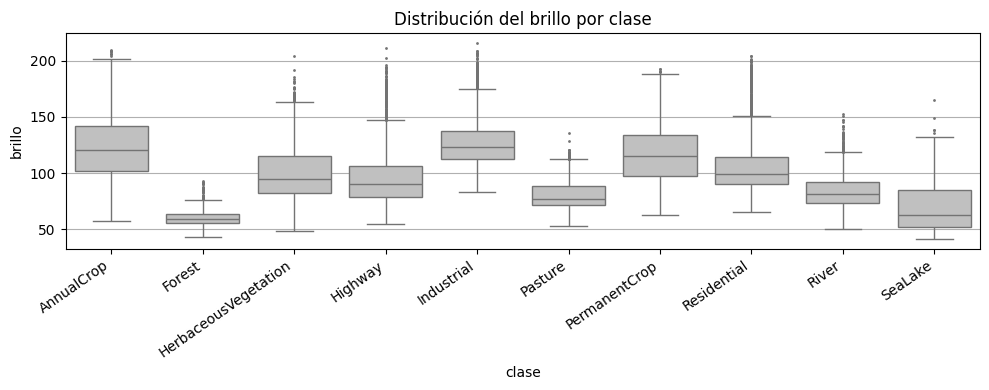

In [11]:
feat = pd.DataFrame({
    "R": X_all[..., 0].mean(axis=(1, 2)),
    "G": X_all[..., 1].mean(axis=(1, 2)),
    "B": X_all[..., 2].mean(axis=(1, 2)),
    "brillo": X_all.mean(axis=(1, 2, 3)),
    "contraste": X_all.reshape(len(X_all), -1).std(axis=1),
    "clase": df["clase"].values,
})
media_clase = feat.groupby("clase")[["R", "G", "B", "brillo", "contraste"]].mean().reindex(CLASSES).round(1)
display(media_clase)

ax = media_clase[["R", "G", "B"]].plot.bar(color=["tab:red", "tab:green", "tab:blue"], figsize=(10, 4))
ax.set_ylabel("Intensidad media (0–255)"); ax.set_title("Intensidad media por canal y clase")
plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
sns.boxplot(data=feat, x="clase", y="brillo", order=CLASSES, color="silver", fliersize=1)
plt.xticks(rotation=35, ha="right"); plt.title("Distribución del brillo por clase")
plt.tight_layout(); plt.show()

Media por canal (R, G, B): [ 87.82  96.97 103.98]
Desviación por canal (R, G, B): [51.68 34.91 29.47]


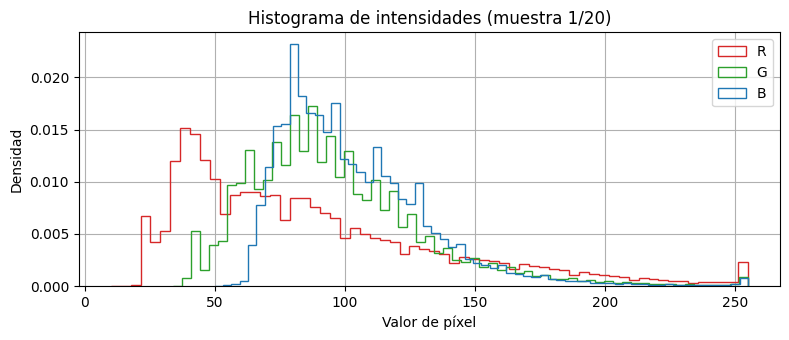

In [12]:
# Estadísticos globales por canal (referencia para normalizar; en el modelo se calcularán solo con entrenamiento)
mu = X_all.reshape(-1, 3).mean(axis=0); sd = X_all.reshape(-1, 3).std(axis=0)
print("Media por canal (R, G, B):", mu.round(2))
print("Desviación por canal (R, G, B):", sd.round(2))

plt.figure(figsize=(8, 3.5))
for ch, col in enumerate(["tab:red", "tab:green", "tab:blue"]):
    plt.hist(X_all[::20, :, :, ch].ravel(), bins=64, histtype="step", color=col, label="RGB"[ch], density=True)
plt.xlabel("Valor de píxel"); plt.ylabel("Densidad"); plt.title("Histograma de intensidades (muestra 1/20)")
plt.legend(); plt.tight_layout(); plt.show()

## 6. Separabilidad: proyección PCA 2D

Se aplanan las imágenes (reducidas a 32 × 32) y se proyectan en dos componentes principales.
Si las clases se mezclan en este espacio lineal, un clasificador lineal sobre píxeles no bastará y se justifica una red convolucional.

Varianza explicada por 2 componentes: 0.672


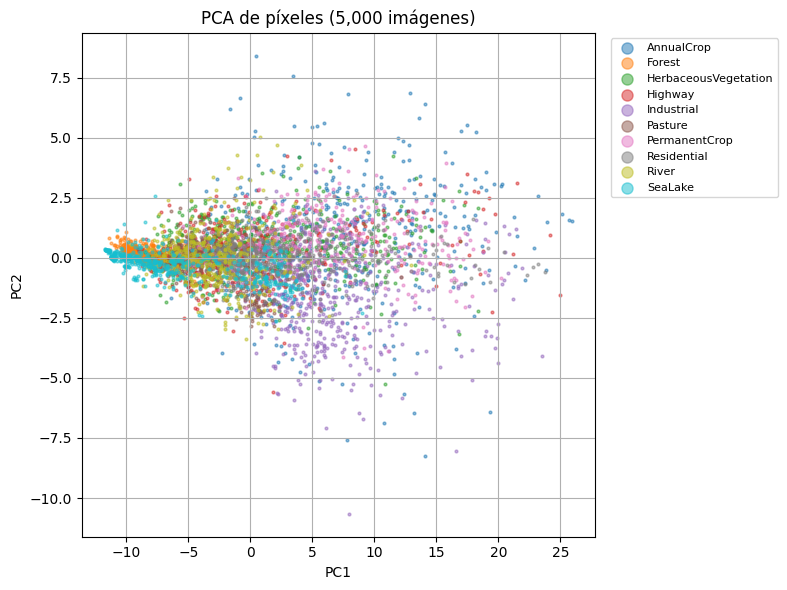

In [13]:
from sklearn.decomposition import PCA

idx = rng.choice(len(X_all), 5000, replace=False)
small = X_all[idx, ::2, ::2, :].reshape(len(idx), -1).astype(np.float32) / 255.0
pca = PCA(n_components=2, random_state=SEED)
Z = pca.fit_transform(small)
print("Varianza explicada por 2 componentes:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
pal = sns.color_palette("tab10", len(CLASSES))
for k, cls in enumerate(CLASSES):
    m = y_all[idx] == k
    plt.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.5, color=pal[k], label=cls)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA de píxeles (5,000 imágenes)")
plt.legend(markerscale=4, fontsize=8, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

## 7. Resumen automático de hallazgos

In [14]:
print(f"""
RESUMEN
- Imágenes: {len(df)} en {df['clase'].nunique()} clases; todas {df['size'].mode()[0]} {df['mode'].mode()[0]}.
- Imágenes ilegibles: {len(bad)} | etiquetas nulas: {int(df['label'].isna().sum())}.
- Duplicados exactos: {int(dup_mask.sum())} imágenes en {grupos.ngroups} grupos.
- Clase menor: {counts.idxmin()} ({counts.min()}); clase mayor: {counts.idxmax()} ({counts.max()}); razón {counts.max()/counts.min():.2f}.
- Cumple requisitos: >= 2,000 imágenes ({len(df) >= 2000}) y >= 200 por clase ({counts.min() >= 200}).
- Clase más oscura: {media_clase['brillo'].idxmin()} | más brillante: {media_clase['brillo'].idxmax()}.
""")


RESUMEN
- Imágenes: 27000 en 10 clases; todas (64, 64) RGB.
- Imágenes ilegibles: 0 | etiquetas nulas: 0.
- Duplicados exactos: 0 imágenes en 0 grupos.
- Clase menor: Pasture (2000); clase mayor: AnnualCrop (3000); razón 1.50.
- Cumple requisitos: >= 2,000 imágenes (True) y >= 200 por clase (True).
- Clase más oscura: Forest | más brillante: Industrial.



## 8. Interpretación e implicaciones para el proyecto

1. **Tamaño suficiente.** 27,000 imágenes y al menos 2,000 por clase.
2. **Desbalance moderado (≈1.5 : 1).** Pasture es la clase menor. Se usará partición **estratificada** y se reportarán precisión, recall y **F1 macro**, además de la exactitud.
3. **Calidad.** Revisar las salidas de la sección 2: si hay duplicados exactos, se eliminarán antes de dividir para evitar fuga entre entrenamiento y prueba.
4. **Imágenes pequeñas (64 × 64).** Una CNN desde cero puede trabajar a esa resolución. Para ResNet-50 preentrenada se reescalará a 224 × 224.
5. **Clases parecidas.** AnnualCrop/PermanentCrop, Pasture/HerbaceousVegetation y Highway/River comparten color o forma lineal; se espera que concentren los errores.
6. **El color no basta.** SeaLake y Forest destacan por ser oscuras, pero el resto se traslapa en color y en la proyección PCA. Hay que aprender textura y forma espacial: se justifica una red convolucional.
7. **Sin orientación canónica.** Las vistas satelitales no tienen "arriba"; volteos y rotaciones de 90° son aumentos válidos que no cambian la clase.
8. **Normalización sin fuga.** La media y desviación por canal se calcularán solo con el conjunto de entrenamiento.